In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats
import seaborn as sns
import plotly.express as px


In [2]:
df_norag = pd.read_csv('5x5Data/dynarapid_5x5_norag.csv')
# df_rag = pd.read_csv('5x5Data/vitis_5x5_norag.csv')

df_norag = df_norag.sort_values(by=['model', 'run', 'kernel', 'attempt'])

df_norag['model'] = df_norag['model'].str.split('/').str[-1]
df_norag['cumulative_success_dcp'] = df_norag.groupby(['model', 'run', 'kernel'])['has_dcp'].cummax()

# print(df_norag)
full_success_rate_dcp = df_norag.groupby(['model', 'run', 'attempt'])['cumulative_success_dcp'].mean().reset_index()


# Rename the column for clarity
full_success_rate_dcp.rename(
    columns={'cumulative_success_dcp': 'Pass@K DCP Generation Rate'}, 
    inplace=True
)


rate_by_group = df_norag.groupby(['model','attempt'])['cumulative_success_dcp'].mean().reset_index()
final_plot_data = full_success_rate_dcp.groupby(['model', 'attempt'])['Pass@K DCP Generation Rate'].agg(['mean', 'std']).reset_index()
final_plot_data.rename(
    columns={'mean': 'Average Generation Rate', 'std': 'SD'}, 
    inplace=True
)

def avg_by_attempt(df, runNum):
    df_run = df[df['run']==runNum].copy()
    avg_by_attempt = df_run.groupby(['model','attempt']).agg({
        'cumulative_success_dcp': 'mean'
    }).reset_index().rename(columns={
        'cumulative_success_dcp': 'avg_dcp_generation'
    })
    return avg_by_attempt

# 1) For each model/kernel/attempt, find whether ANY run had succeeded by that attempt
group_cols = ['model', 'kernel', 'attempt']
anyrun_max_dcp = df_norag.groupby(group_cols)['cumulative_success_dcp'].max().reset_index(name='anyrun_max_dcp')
anyrun = anyrun_max_dcp
anyrun = anyrun.sort_values(by=['model', 'kernel', 'attempt'])
anyrun['anyrun_cummax_dcp'] = anyrun.groupby(['model', 'kernel'])['anyrun_max_dcp'].cummax()
pass_at_k_anyrun_dcp = anyrun.groupby(['model', 'attempt'])['anyrun_cummax_dcp'].mean().reset_index()



model_names = {
    "gpt-4.1-mini": "GPT-4.1 mini",
    "grok-code-fast-1": "Grok Code Fast",
    "gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek-r1-0528": "Deepseek R1",
    "qwen3-coder": "Qwen3 Coder",
    "grok-4": "Grok 4",
    "gemini-2.5-pro": "Gemini 2.5 Pro",
    "claude-sonnet-4.5": "Claude Sonnet 4.5",
    "gpt-5": "GPT 5"
}
full_success_rate_dcp['model'] = full_success_rate_dcp['model'].map(model_names)




                model  run  attempt  Pass@K DCP Generation Rate
0   Claude Sonnet 4.5    1        1                    0.433333
1   Claude Sonnet 4.5    1        2                    0.700000
2   Claude Sonnet 4.5    1        3                    0.833333
3   Claude Sonnet 4.5    1        4                    0.866667
4   Claude Sonnet 4.5    1        5                    0.866667
..                ...  ...      ...                         ...
70       GPT-4.1 mini    5        1                    0.466667
71       GPT-4.1 mini    5        2                    0.566667
72       GPT-4.1 mini    5        3                    0.733333
73       GPT-4.1 mini    5        4                    0.800000
74       GPT-4.1 mini    5        5                    0.900000

[75 rows x 4 columns]


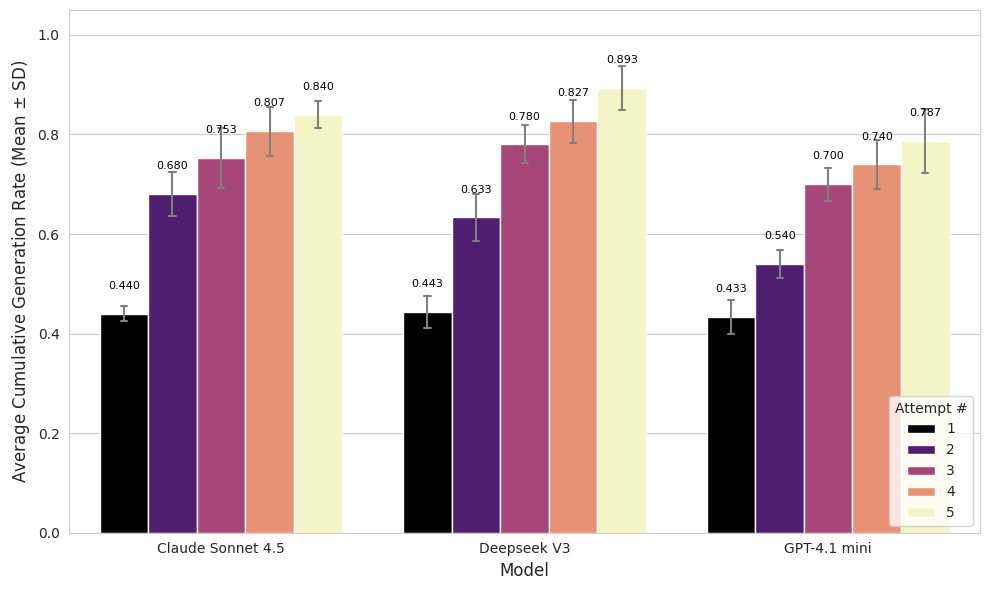

In [3]:
# Set a clean plotting style
sns.set_style("whitegrid")

plt.figure(figsize=(10, 6))
print(full_success_rate_dcp)

# Use barplot:
ax = sns.barplot(
    data=full_success_rate_dcp, 
    x='model', 
    y='Pass@K DCP Generation Rate', 
    hue='attempt',           # Key: Plots separate, grouped bars for each model
    errorbar='sd',         # Key: Calculates and displays the Standard Deviation (whiskers)
    err_kws={'color': 'gray', 'linewidth': 1.5},
    capsize=0.1,           # Adds small caps to the whiskers for clarity
    palette='magma'      # Use a distinct color palette
)

for p in ax.patches:
    # Get the mean value (height of the bar)
    mean_value = p.get_height()
    
    # Only annotate if the bar has a non-zero height
    if mean_value > 0:
        ax.annotate(
            f'{mean_value:.3f}',  # Format the mean to three decimal places
            # Position the text: centered horizontally, slightly above the bar
            (p.get_x() + p.get_width() / 2., mean_value), 
            ha='center', 
            va='center', 
            xytext=(0, 20), # Slight offset above the bar (increased from 5 to 10 for better visibility above the whisker cap)
            textcoords='offset points',
            fontsize=8,
            color='black'
        )

# --- Add Labels and Title ---
# plt.title(
#     'Average Generation Rate Per Attempt (DCP)', 
#     fontsize=16, 
#     fontweight='bold'
# )
plt.xlabel('Model', fontsize=12)
plt.ylabel('Average Cumulative Generation Rate (Mean $\pm$ SD)', fontsize=12)
plt.legend(title='Attempt #', loc='lower right')

# Set Y-axis limit for a proper rate representation
plt.ylim(0, 1.05) 

plt.tight_layout()
plt.savefig("average_dynarapid_success.pdf")
plt.show()

               model  attempt  anyrun_cummax_dcp
0  Claude Sonnet 4.5        1           0.466667
1  Claude Sonnet 4.5        2           0.800000
2  Claude Sonnet 4.5        3           0.866667
3  Claude Sonnet 4.5        4           0.933333
4  Claude Sonnet 4.5        5           0.933333


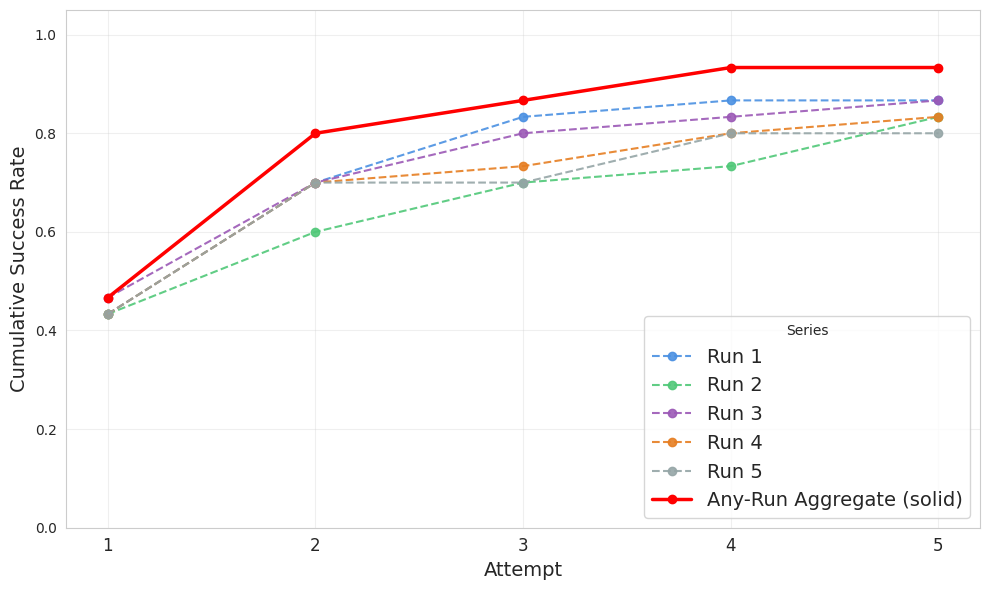

         model  attempt  anyrun_cummax_dcp
5  Deepseek V3        1           0.500000
6  Deepseek V3        2           0.833333
7  Deepseek V3        3           1.000000
8  Deepseek V3        4           1.000000
9  Deepseek V3        5           1.000000


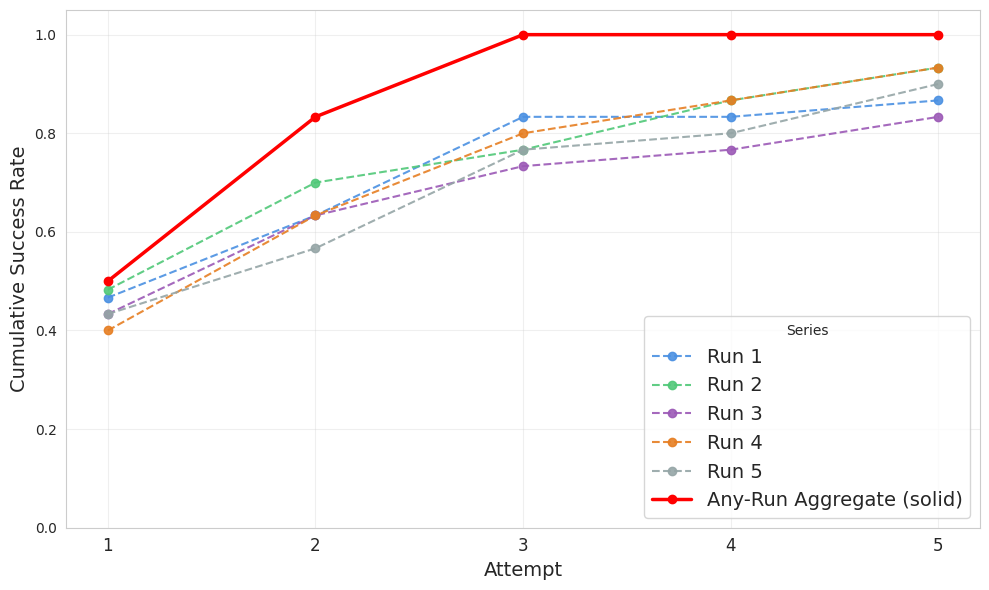

           model  attempt  anyrun_cummax_dcp
10  GPT-4.1 mini        1           0.500000
11  GPT-4.1 mini        2           0.800000
12  GPT-4.1 mini        3           0.866667
13  GPT-4.1 mini        4           0.866667
14  GPT-4.1 mini        5           0.933333


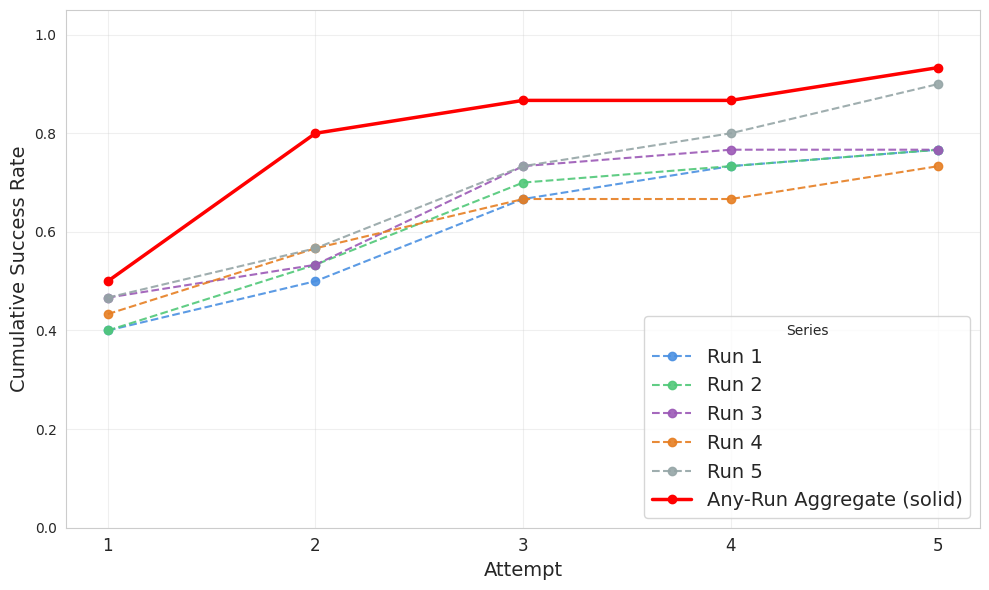

In [4]:
# Making the graph with the attempts separated and with dashed LInes and then the Cummulative on top
# Distinct colors for each trial using different colormaps
trial_colors = ['#4A90E2', '#50C878', '#9B59B6', '#E67E22', '#95A5A6']


df_norag['model'] = df_norag['model'].map(model_names)

run1 = avg_by_attempt(df_norag, 1)
run2 = avg_by_attempt(df_norag, 2)
run3 = avg_by_attempt(df_norag, 3)
run4 = avg_by_attempt(df_norag, 4)
run5 = avg_by_attempt(df_norag, 5)

pass_at_k_anyrun_dcp['model'] = pass_at_k_anyrun_dcp['model'].map(model_names)
passAt5DCP = pass_at_k_anyrun_dcp

models = df_norag['model'].unique()

for model in models:
    plt.figure(figsize=(10,6))
    # plot each run (dashed)
    runs_list = [run1, run2, run3, run4, run5]
    for i, run_df in enumerate(runs_list, start=1):
        dfm = run_df[run_df['model'] == model]
        if dfm.empty:
            continue
        plt.plot(
            dfm['attempt'],
            dfm['avg_dcp_generation'],
            label=f'Run {i}',
            linestyle='--',
            color=trial_colors[i-1],
            marker='o',
            linewidth=1.5,
            alpha=0.9
        )
    # plot aggregate any-run pass@k (solid)
    agg = passAt5DCP[passAt5DCP['model'] == model]
    print(agg)
    if not agg.empty:
        plt.plot(
            agg['attempt'],
            agg['anyrun_cummax_csynth'] if 'anyrun_cummax_csynth' in agg.columns else agg.iloc[:,2],
            label='Any-Run Aggregate (solid)',
            linestyle='-',
            color='red',
            marker='o',
            linewidth=2.5
        )
    
    # plt.title(f'{model} — Avg Cumulative DCP Generation Rate by Attempt\n')
    plt.xlabel('Attempt', fontsize = 14)
    plt.ylabel('Cumulative Success Rate', fontsize = 14)
    plt.xticks(np.arange(1, 6), fontsize = 12)
    plt.ylim(0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend(title='Series', loc='lower right', fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{model}_cumulative_success_dynarapid.pdf")
    plt.show()